# WellbeingIQ · Notebook 1: Data Cleaning & Preparation
**Capstone Project 2 · AI-Powered Student Wellness Prediction and Guidance System**

**Goal:** audit the dataset, fix data-quality problems, define the target (wellness category) and prepare a clean file for modeling.

> **Data note:** `WellbeingIQ_Synthetic_Student_Dataset.xlsx` is a **synthetic** dataset (Python simulation, seed 42) with column design informed by public student-wellbeing datasets. It contains no real students. Findings describe the simulated data, not real people. Not a medical tool.

**Design choices**
- Cleaning here is *deterministic* (duplicates, text, impossible values). **Missing values are NOT imputed here**; imputation happens later inside the modeling pipeline, fitted on training data only, to avoid leakage.
- Every change is written to a cleaning log.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
pd.set_option('display.max_columns',50); sns.set_theme(style='whitegrid')
raw = pd.read_csv('WellbeingIQ_Synthetic_Student_Dataset.csv')
df = raw.copy(); log = []
def record(step, n, note=''): log.append({'Step':step,'Rows/values affected':int(n),'Note':note})
print(raw.shape); raw.head()

(6050, 27)


,Student_ID,Age,Gender,Country,Academic_Level,Residence,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Total_Screen_Time_Hours,Gaming_Hours,Daily_Unlocks,Notifications_Per_Day,Late_Night_Usage_Hours,Study_Hours,Sleep_Hours_Per_Night,Sleep_Quality,Caffeine_Cups_Per_Day,Physical_Activity_Hours,Days_Offline_Per_Month,Social_Support_Score,Academic_Pressure,Academic_Performance_Pct,Conflicts_Over_Social_Media,Addiction_Score,Stress_Level,Mental_Health_Score
0,S00001,21,Female,Indonesia,Undergraduate,Hostel,Instagram,Entertainment,5.4,7.4,1.0,97,105,1.6,6.5,5.8,2.0,4.0,0.2,2.0,5.0,6,85.7,1,7,High,4.5
1,S00002,22,Female,Indonesia,Undergraduate,Hostel,WhatsApp,Mixed,3.2,7.5,1.9,65,149,0.0,2.5,7.8,3.0,NaN,1.6,3.0,9.0,4,77.0,2,5,Low,9.0
2,S00003,18,Male,Nigeria,High School,Rented room,YouTube,Social connection,4.5,8.4,1.8,122,121,1.9,4.3,5.1,1.0,4.0,0.7,2.0,4.0,6,59.8,3,6,High,4.0
3,S00004,18,Female,Indonesia,High School,Home,WhatsApp,Entertainment,5.8,8.7,0.4,113,200,1.3,2.1,6.4,5.0,0.0,NaN,3.0,6.0,4,66.1,3,5,Medium,6.1
4,S00005,22,Female,USA,Undergraduate,Rented room,TikTok,Social connection,0.5,3.2,0.8,10,43,0.0,6.8,7.7,1.0,4.0,1.8,0.0,7.0,4,74.4,0,2,Low,10.0


## 1. First look

In [2]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 6050 entries, 0 to 6049
Data columns (total 27 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Student_ID                   6050 non-null   str    
 1   Age                          6050 non-null   int64  
 2   Gender                       6050 non-null   str    
 3   Country                      6050 non-null   str    
 4   Academic_Level               6050 non-null   str    
 5   Residence                    6050 non-null   str    
 6   Most_Used_Platform           6050 non-null   str    
 7   Purpose_Of_Use               6050 non-null   str    
 8   Avg_Daily_Usage_Hours        6050 non-null   float64
 9   Total_Screen_Time_Hours      6050 non-null   float64
 10  Gaming_Hours                 6050 non-null   float64
 11  Daily_Unlocks                6050 non-null   int64  
 12  Notifications_Per_Day        6050 non-null   int64  
 13  Late_Night_Usage_Hours       

In [3]:
raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Age,6050.0,21.62,2.86,5.0,20.0,22.0,23.0,99.0
Avg_Daily_Usage_Hours,6050.0,3.61,1.68,0.5,2.5,3.6,4.6,22.0
Total_Screen_Time_Hours,6050.0,7.01,2.54,0.1,5.3,7.0,8.7,16.0
Gaming_Hours,6050.0,0.93,0.83,0.0,0.4,0.7,1.3,6.0
Daily_Unlocks,6050.0,95.24,35.79,10.0,71.0,95.0,119.0,229.0
Notifications_Per_Day,6050.0,124.06,49.13,5.0,90.0,123.0,157.0,318.0
Late_Night_Usage_Hours,6050.0,0.86,0.57,0.0,0.4,0.8,1.3,3.2
Study_Hours,6050.0,4.35,1.62,0.0,3.3,4.3,5.5,11.9
Sleep_Hours_Per_Night,6050.0,6.92,1.02,3.5,6.3,6.9,7.6,18.0
Sleep_Quality,5900.0,2.70,0.97,1.0,2.0,3.0,3.0,5.0


## 2. Data-quality audit (before cleaning)

In [4]:
miss = raw.isna().sum(); miss = miss[miss>0].to_frame('missing'); miss['pct']=(miss.missing/len(raw)*100).round(2)
print('Exact duplicate rows:', raw.duplicated().sum(), '| duplicate Student_IDs:', raw.Student_ID.duplicated().sum())
miss

Exact duplicate rows: 50 | duplicate Student_IDs: 50


,missing,pct
Sleep_Quality,150,2.48
Caffeine_Cups_Per_Day,122,2.02
Physical_Activity_Hours,90,1.49
Days_Offline_Per_Month,121,2.00
Social_Support_Score,181,2.99
Academic_Performance_Pct,150,2.48


In [5]:
print(raw.Country.value_counts().to_string()); print(); print(raw.Gender.value_counts().to_string())

Country
India           1770
USA              620
Pakistan         592
Bangladesh       550
Egypt            534
Nigeria          469
Indonesia        435
UK               390
Brazil           346
Philippines      304
india             10
indonesia          6
usa                6
pakistan           5
egypt              4
bangladesh         3
brazil             2
uk                 2
philippines        1
nigeria            1

Gender
Female    3066
Male      2773
Other      180
male        16
female      15


In [6]:
# plausibility rules for student habit data (bounds are deliberately generous)
RULES = {'Age':(16,35),'Sleep_Hours_Per_Night':(2,12),'Avg_Daily_Usage_Hours':(0,16),
         'Total_Screen_Time_Hours':(0,20),'Study_Hours':(0,14),'Physical_Activity_Hours':(0,6),'Gaming_Hours':(0,10)}
viol = {c:int(((raw[c]<lo)|(raw[c]>hi)).sum()) for c,(lo,hi) in RULES.items()}
viol['Total screen < social media usage'] = int((raw.Total_Screen_Time_Hours < raw.Avg_Daily_Usage_Hours).sum())
pd.Series(viol, name='violations').to_frame()

,violations
Age,8
Sleep_Hours_Per_Night,12
Avg_Daily_Usage_Hours,10
Total_Screen_Time_Hours,0
Study_Hours,0
Physical_Activity_Hours,0
Gaming_Hours,0
Total screen < social media usage,35


## 3. Cleaning

In [7]:
# 3.1 exact duplicates
n = df.duplicated().sum(); df = df.drop_duplicates().reset_index(drop=True)
record('Drop exact duplicate rows', n, 'kept first occurrence'); print('removed', n, '| rows now', len(df), '| Student_ID unique:', df.Student_ID.is_unique)

removed 50 | rows now 6000 | Student_ID unique: True


In [8]:
# 3.2 standardize text categories (map every spelling to the most common one, so acronyms like USA / UK stay intact)
country_before = df.Country.copy(); gender_before = df.Gender.copy()
key = df.Country.str.strip().str.lower()
canon = df.assign(k=key).groupby('k').Country.agg(lambda s: s.str.strip().value_counts().index[0])
df['Country'] = key.map(canon)
df['Gender'] = df.Gender.str.strip().str.title()
changed = int((country_before != df.Country).sum() + (gender_before != df.Gender).sum())
record('Standardize Country / Gender text', changed, 'lowercase / trailing-space variants mapped to the main spelling')
print(sorted(df.Country.unique())); print(df.Gender.unique())

['Bangladesh', 'Brazil', 'Egypt', 'India', 'Indonesia', 'Nigeria', 'Pakistan', 'Philippines', 'UK', 'USA']
<StringArray>
['Female', 'Male', 'Other']
Length: 3, dtype: str


In [9]:
# 3.3 impossible values -> NaN (imputed later, inside the train pipeline)
for c,(lo,hi) in RULES.items():
    bad = (df[c]<lo)|(df[c]>hi)
    record(f'Invalid {c} set to NaN', bad.sum(), f'allowed {lo} to {hi}'); df.loc[bad,c] = np.nan
bad = df.Total_Screen_Time_Hours < df.Avg_Daily_Usage_Hours
record('Total screen < social media usage -> Total_Screen set to NaN', bad.sum(), 'logically impossible'); df.loc[bad,'Total_Screen_Time_Hours']=np.nan
print('values set to NaN:', sum(l['Rows/values affected'] for l in log[2:]))

values set to NaN: 55


In [10]:
# 3.4 integer-like columns stay numeric; ordinal scales sanity check
for c,(lo,hi) in {'Sleep_Quality':(1,5),'Social_Support_Score':(1,10),'Academic_Pressure':(1,10),'Conflicts_Over_Social_Media':(0,5),'Addiction_Score':(1,10),'Mental_Health_Score':(1,10)}.items():
    print(f'{c:30s} outside {lo}-{hi}:', int(((df[c]<lo)|(df[c]>hi)).sum()))

Sleep_Quality                  outside 1-5: 0
Social_Support_Score           outside 1-10: 0
Academic_Pressure              outside 1-10: 0
Conflicts_Over_Social_Media    outside 0-5: 0
Addiction_Score                outside 1-10: 0
Mental_Health_Score            outside 1-10: 0


## 4. Outlier review (information only; the data is plausible after step 3, so nothing more is removed)

In [11]:
num = df.select_dtypes('number').columns
q1,q3 = df[num].quantile(.25), df[num].quantile(.75); iqr=q3-q1
out = ((df[num]<q1-1.5*iqr)|(df[num]>q3+1.5*iqr)).sum().sort_values(ascending=False)
out[out>0].to_frame('IQR outliers').T

,Gaming_Hours,Sleep_Quality,Conflicts_Over_Social_Media,Days_Offline_Per_Month,Age,Total_Screen_Time_Hours,Sleep_Hours_Per_Night,Mental_Health_Score,Daily_Unlocks,Avg_Daily_Usage_Hours,Notifications_Per_Day,Social_Support_Score,Addiction_Score,Study_Hours,Caffeine_Cups_Per_Day,Physical_Activity_Hours,Academic_Performance_Pct,Late_Night_Usage_Hours
IQR outliers,264,173,109,106,58,35,34,31,29,24,23,23,19,18,17,15,13,11


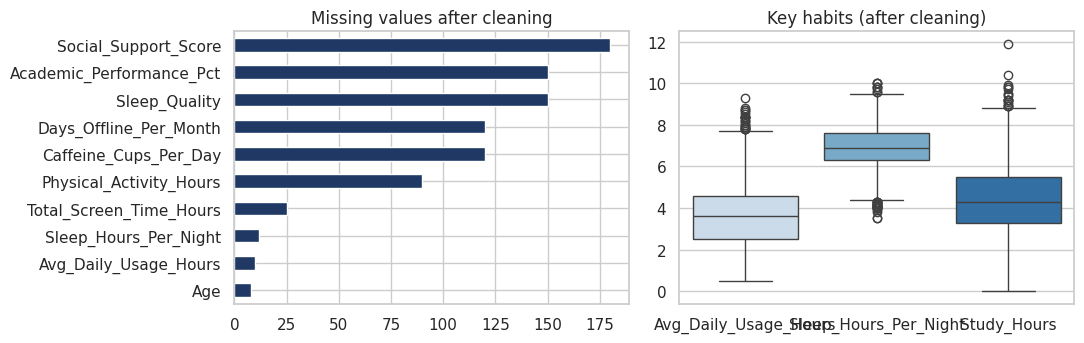

In [12]:
fig,ax = plt.subplots(1,2,figsize=(11,3.6))
df.isna().sum()[lambda s:s>0].sort_values().plot.barh(ax=ax[0],color='#1F3864'); ax[0].set_title('Missing values after cleaning')
sns.boxplot(data=df[['Avg_Daily_Usage_Hours','Sleep_Hours_Per_Night','Study_Hours']],ax=ax[1],palette='Blues'); ax[1].set_title('Key habits (after cleaning)')
plt.tight_layout(); plt.show()

## 5. Target definition
The proposal asks for **wellness categories**. `Mental_Health_Score` (1 to 10, higher = better) is converted into three ordered classes:

| Class | Score | Meaning |
|---|---|---|
| At-Risk | below 5.5 | low wellbeing, needs attention |
| Moderate | 5.5 to below 7.5 | middle |
| Good | 7.5 and above | good wellbeing |

Round cut-offs were chosen on the 1 to 10 scale and checked for class balance. They are a modeling choice, not clinical thresholds, so we will test sensitivity later.

,students,pct
Wellness_Category,,
At-Risk,1136,18.9
Moderate,2904,48.4
Good,1960,32.7


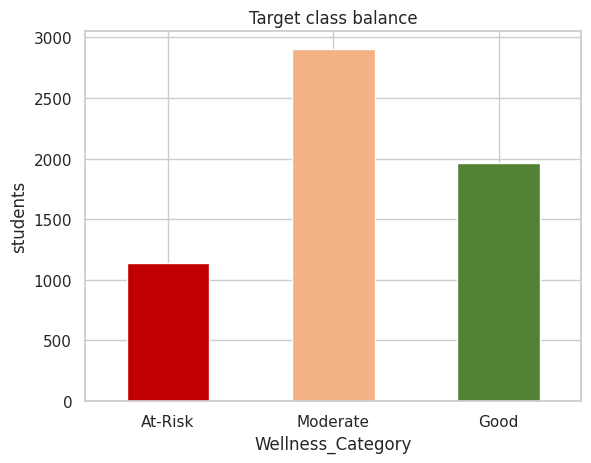

In [13]:
LO, HI = 5.5, 7.5
df['Wellness_Category'] = pd.cut(df.Mental_Health_Score, [-np.inf,LO,HI,np.inf], labels=['At-Risk','Moderate','Good'], right=False)
dist = df.Wellness_Category.value_counts().reindex(['At-Risk','Moderate','Good'])
display((dist.to_frame('students').assign(pct=(dist/len(df)*100).round(1))))
dist.plot.bar(color=['#C00000','#F4B183','#548235'],rot=0); plt.title('Target class balance'); plt.ylabel('students'); plt.show()

## 6. Feature decisions (leakage control)
| Column | Decision | Reason |
|---|---|---|
| Student_ID | drop | identifier |
| Mental_Health_Score | drop from features | the target category is built from it |
| Stress_Level | **drop from features** | derived partly from the wellbeing score in the simulation, so it would leak the answer |
| Addiction_Score | keep, but test with and without | a proxy of usage, not target-derived; we will measure its effect (ablation) |
| Everything else | keep | habit, lifestyle and demographic inputs |
Gender and Country had no effect on the score in the simulation; we still keep them in the first model and check them later with SHAP.

In [14]:
DROP = ['Student_ID','Mental_Health_Score','Stress_Level']
features = [c for c in df.columns if c not in DROP+['Wellness_Category']]
print(len(features),'model features:'); print(features)

24 model features:
['Age', 'Gender', 'Country', 'Academic_Level', 'Residence', 'Most_Used_Platform', 'Purpose_Of_Use', 'Avg_Daily_Usage_Hours', 'Total_Screen_Time_Hours', 'Gaming_Hours', 'Daily_Unlocks', 'Notifications_Per_Day', 'Late_Night_Usage_Hours', 'Study_Hours', 'Sleep_Hours_Per_Night', 'Sleep_Quality', 'Caffeine_Cups_Per_Day', 'Physical_Activity_Hours', 'Days_Offline_Per_Month', 'Social_Support_Score', 'Academic_Pressure', 'Academic_Performance_Pct', 'Conflicts_Over_Social_Media', 'Addiction_Score']


## 7. Save outputs

In [15]:
df.to_csv('WellbeingIQ_cleaned.csv', index=False)
cl = pd.DataFrame(log); cl.to_csv('cleaning_log.csv', index=False)
summary = pd.DataFrame({'Rows':[len(raw),len(df)],'Columns':[raw.shape[1],df.shape[1]],'Missing cells':[int(raw.isna().sum().sum()),int(df.isna().sum().sum())]}, index=['Before','After'])
display(summary); display(cl)

,Rows,Columns,Missing cells
Before,6050,27,814
After,6000,28,865


,Step,Rows/values affected,Note
0,Drop exact duplicate rows,50,kept first occurrence
1,Standardize Country / Gender text,70,lowercase / trailing-space variants mapped to ...
2,Invalid Age set to NaN,8,allowed 16 to 35
3,Invalid Sleep_Hours_Per_Night set to NaN,12,allowed 2 to 12
4,Invalid Avg_Daily_Usage_Hours set to NaN,10,allowed 0 to 16
5,Invalid Total_Screen_Time_Hours set to NaN,0,allowed 0 to 20
6,Invalid Study_Hours set to NaN,0,allowed 0 to 14
7,Invalid Physical_Activity_Hours set to NaN,0,allowed 0 to 6
8,Invalid Gaming_Hours set to NaN,0,allowed 0 to 10
9,Total screen < social media usage -> Total_Scr...,25,logically impossible


## 8. Summary
- Exact duplicates removed, text categories standardized, impossible values turned into missing values (not guessed).
- Remaining missing values will be imputed **inside the modeling pipeline using training data only**.
- Target `Wellness_Category` created (At-Risk / Moderate / Good) and checked for balance.
- `Stress_Level` excluded from features to prevent leakage; `Addiction_Score` kept for an ablation test.

**Next:** Notebook 2, exploratory data analysis and business insights.